In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1. Carga de datos multivariados (Ejemplo: Registros Meteorológicos usando read_excel)
df = pd.read_excel('datos_estaciones_meteorologicas_tema9.xlsx', index_col='estacion')
num_cols = ['temperatura_c', 'humedad_pct', 'precipitacion_mm', 'altitud_m']

# 2. Imputación de valores faltantes con la mediana
df_clean = df[num_cols].fillna(df[num_cols].median())

# 3. Estandarización Z-Score (Media=0, DesvEst=1)
scaler_z = StandardScaler()
df_z = pd.DataFrame(scaler_z.fit_transform(df_clean), 
                    index=df_clean.index, columns=df_clean.columns)

# 4. Escalamiento Min-Max (Rango [0, 1])
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_minmax.fit_transform(df_clean), 
                         index=df_clean.index, columns=df_clean.columns)

print("--- Matriz Estandarizada Z-Score ---")
print(df_z.head())

--- Matriz Estandarizada Z-Score ---
               temperatura_c  humedad_pct  precipitacion_mm  altitud_m
estacion                                                              
Cusco               0.000000     0.202444          0.586077   0.441190
Pisaq               1.030036    -0.506110         -0.750911  -0.699864
Urubamba            1.765775     0.910998         -0.164834  -0.972435
Ollantaytambo       0.000000     1.720775          1.062264  -1.180871
Sicuani            -0.735740    -1.315887         -1.318672   0.844701


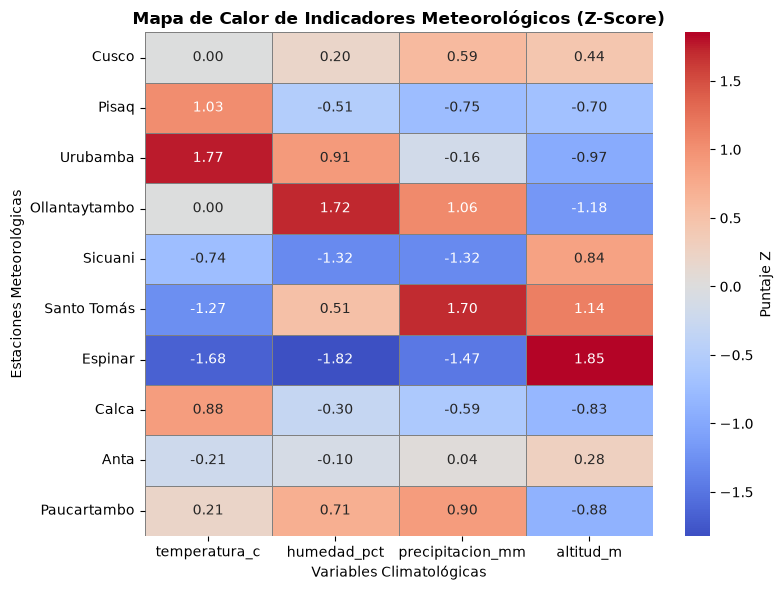

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Mapa de Calor con Paleta Divergente 'coolwarm' centrada en 0 (Z-Score)
sns.heatmap(df_z, 
            cmap='coolwarm', 
            center=0, 
            annot=True, 
            fmt='.2f', 
            linewidths=0.5, 
            linecolor='gray',
            cbar_kws={'label': 'Puntaje Z'})

plt.title('Mapa de Calor de Indicadores Meteorológicos (Z-Score)', fontsize=12, fontweight='bold')
plt.xlabel('Variables Climatológicas')
plt.ylabel('Estaciones Meteorológicas')
plt.tight_layout()
plt.show()



AttributeError: 'ClusterGrid' object has no attribute 'ax_title'

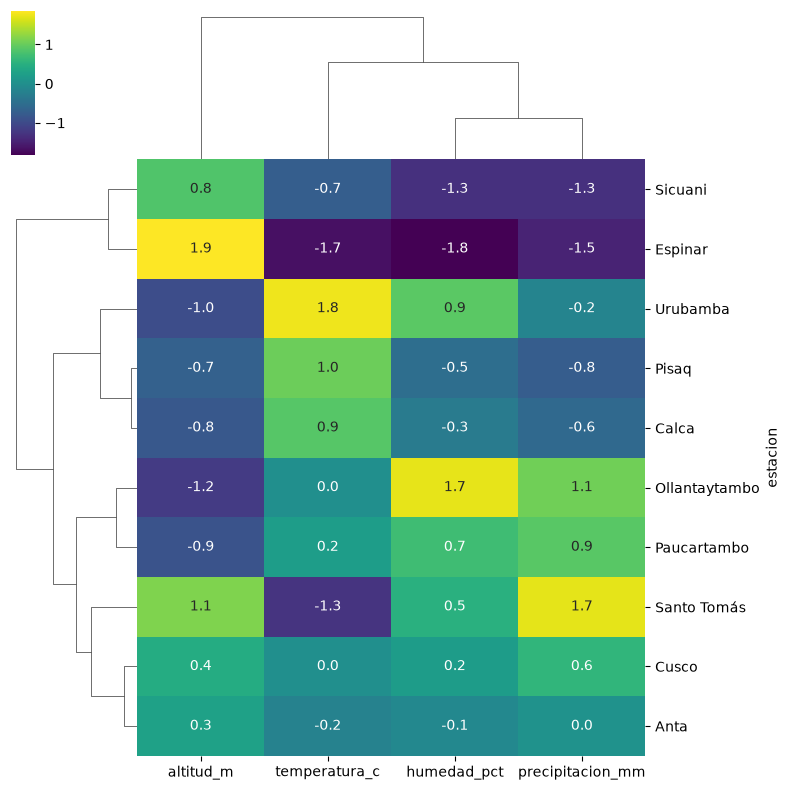

In [3]:
# Clustermap con Clustering Jerárquico (Métrica Euclidiana, Enlace Ward)
g = sns.clustermap(df_z,
                   metric='euclidean',
                   method='ward',
                   cmap='viridis',
                   annot=True,
                   fmt='.1f',
                   figsize=(8, 8),
                   dendrogram_ratio=(0.2, 0.2),
                   cbar_pos=(0.02, 0.8, 0.03, 0.18))

g.ax_title.set_title('Clustermap con Dendrogramas de Filas y Columnas', fontsize=12, fontweight='bold')
plt.show()



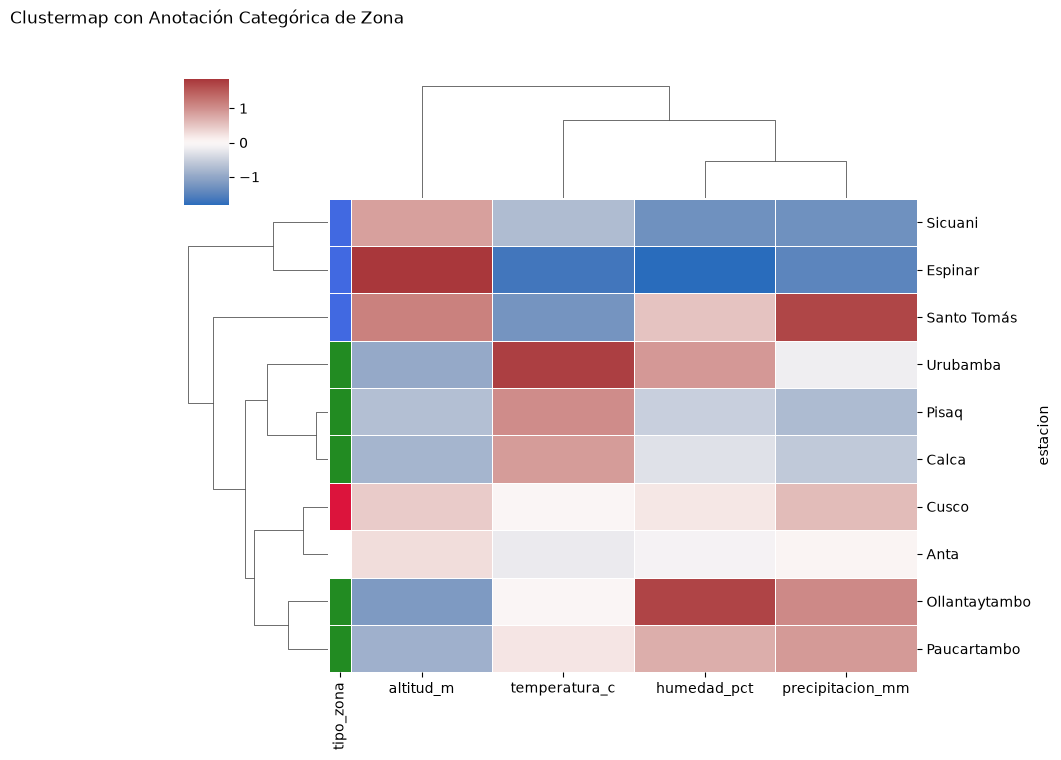

In [5]:
# Definición de barra de colores para anotación categórica
zona_colors = df['tipo_zona'].map({'Urbana': 'crimson', 'Valle': 'forestgreen', 'Altoandina': 'royalblue'})

g_annot = sns.clustermap(df_z,
                         row_colors=zona_colors,
                         cmap='vlag',
                         center=0,
                         linewidths=0.5,
                         figsize=(9, 7))

plt.title('Clustermap con Anotación Categórica de Zona', pad=40)
plt.show()



Imagen exportada exitosamente como 'mapa_calor_correlacion_hd.png'.


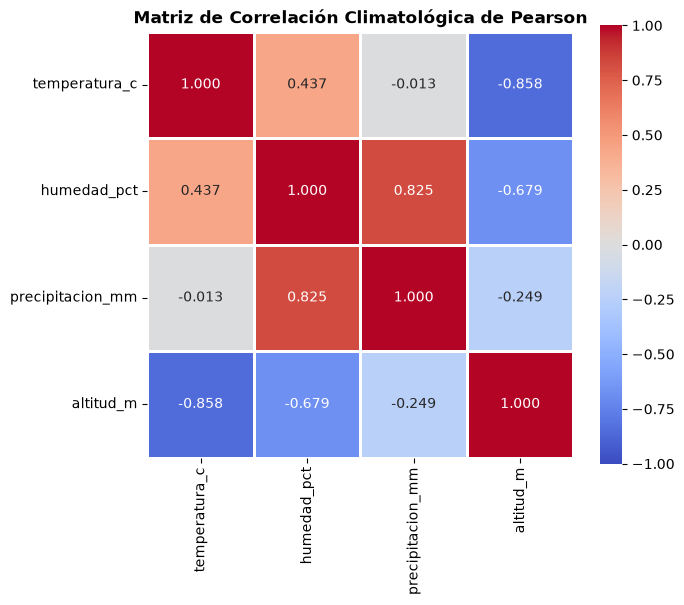

In [4]:
# Matriz de Correlación de Pearson
corr_matrix = df_clean.corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, 
            annot=True, 
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            fmt='.3f',
            square=True, 
            linewidths=1.0)

plt.title('Matriz de Correlación Climatológica de Pearson', fontsize=12, fontweight='bold')
plt.tight_layout()

# Exportación en Alta Resolución (300 DPI)
plt.savefig('mapa_calor_correlacion_hd.png', dpi=300, bbox_inches='tight')
print("Imagen exportada exitosamente como 'mapa_calor_correlacion_hd.png'.")
